# 07 — Temporal Data Drift Analysis (Partie 7)
### Points 53 à 64 du plan : période de référence, fenêtres fixes, distributions par période, évolution des statistiques, PSI, KS, Wasserstein, Jensen-Shannon, drift par feature, heatmap, drift normal contre attaques, features instables

| | |
|---|---|
| **Question de la partie** | *Les données de « production » ressemblent-elles aux données d'entraînement ? Quelles variables bougent, de combien, et un détecteur de drift naïf serait-il utilisable ?* |
| **Entrées** | les 6 fichiers HAI en **unités physiques**, découpés en fenêtres d'une heure |
| **Sorties** | `reports/drift_feature_stability.csv`, `reports/drift_thresholds.json`, `reports/drift_windows.csv`, figures `reports/figures/7x_*` |
| **Lien avec le cahier** | F18 (Data Drift), F19 (dégradation du modèle), F21 (Decision Engine) |

> **Règles d'usage des données (anti-fuite).**
> - La **référence** et les **seuils de drift** sont calculés sur le **train uniquement**.
> - Les sessions *train3* et *train4* (normales, postérieures) servent de **production normale** : c'est là qu'on mesure combien un détecteur de drift déclencherait *à tort*.
> - Les labels des fichiers de test ne sont utilisés qu'à la section **63** (comparaison drift / attaques), de façon **descriptive** : **test1** pour décider, **test2** en lecture seule. Aucune variable n'est retenue ni écartée à cause d'eux.

### Les quatre mesures, et pourquoi quatre
| Mesure | Ce qu'elle compare | Lecture | Limite |
|---|---|---|---|
| **PSI** | part de points dans chaque classe (déciles de la référence), entre référence et fenêtre | Σ (p_fen − p_réf) · ln(p_fen / p_réf) ; règles empiriques 0,1 (modéré) et 0,25 (fort), héritées du scoring de crédit | dépend du découpage en classes |
| **KS** | écart maximal entre les fonctions de répartition | de 0 à 1 | la p-value est **inutilisable** sur de grands échantillons (voir §58) |
| **Wasserstein normalisée** | « travail » pour transformer une distribution en l'autre, divisé par l'écart-type de la référence | décalage moyen **en écarts-types** : lecture physique directe | sensible aux valeurs extrêmes |
| **Jensen-Shannon** | divergence symétrique entre les distributions par classes | de 0 (identiques) à 1 (disjointes) | dépend du découpage en classes |

Aucune n'est « la bonne » : on les compare, et surtout **on les rapporte à une fluctuation normale** (seuil nul mesuré sur la référence elle-même) au lieu de se fier à des seuils conventionnels.

## 0. Configuration et chargement

In [12]:
from pathlib import Path
import json, sys, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "params.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
try:
    from src.data.io import find_hai_files, load_hai_csv, sensor_columns
    from src.data.prep import clean_file
    from src.data.catalog import segments
    from src.eda import drift as DR, tools as T
except ImportError as e:
    raise ImportError("Lance Jupyter depuis le dossier du projet (celui qui contient params.yaml et src/). Détail : " + str(e))

DATA_ROOT = ROOT / "data" / "raw"; REPORT_DIR = ROOT / "reports"; FIG_DIR = REPORT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
VERSION_TAG, SEED = "23.05", 42
STRICT_OFFICIAL_CHECKS = True            # False UNIQUEMENT pour un test à blanc sur données de démo
REF_FILES = ("train1",)        # §53 : période de référence = données d'entraînement
WINDOW_S = 3600                          # §54 : fenêtres fixes d'une heure
BINS, NULL_Q = 10, 0.95                  # classes de PSI/JS (déciles de la référence) ; quantile du seuil nul
PSI_MOD, PSI_STRONG = 0.10, 0.25         # règles empiriques conventionnelles (à ne pas prendre pour des lois)
PRE_S, N_PLACEBO = 300, 3                # §63 : baseline locale de 5 min ; fenêtres normales (placebo) par attaque
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold"})
PAL = {"ref": "#2f6fb3", "prod": "#5bb4a6", "attack": "#d9534f", "grey": "#9aa3ad", "warn": "#f0ad4e", "viol": "#8e5ea2"}
FINDINGS, EV = [], {}
def insight(topic, msg): FINDINGS.append((topic, msg)); print(f"💡 [{topic}] {msg}")
def savefig(name): plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()

In [13]:
FILES = find_hai_files(DATA_ROOT, VERSION_TAG, allow_unversioned=not STRICT_OFFICIAL_CHECKS)
LABEL_INFO, clean = {}, {}
for k in ("train1", "train2", "train3", "train4", "test1", "test2"):
    lab = FILES.get(f"label-{k}") if k.startswith("test") else None
    clean[k] = clean_file(load_hai_csv(FILES[f"hai-{k}"], lab, LABEL_INFO), 1, 5)                  # unités PHYSIQUES : aucune normalisation
ORDER = sorted(clean, key=lambda k: clean[k].timestamp.min())                                         # ordre chronologique réel
print("ordre chronologique :", " → ".join(ORDER), "|", {k: v.shape for k, v in clean.items()})

ordre chronologique : train1 → test1 → train2 → test2 → train3 → train4 | {'train1': (280800, 87), 'train2': (291600, 87), 'train3': (126000, 87), 'train4': (198000, 87), 'test1': (54000, 88), 'test2': (230400, 88)}


## 53. Définition de la période de référence
**Pourquoi.** « Drift » n'a de sens que **par rapport à** une distribution de référence. Dans le cahier des charges (F18), la référence est *la distribution des données d'entraînement* ; on compare ensuite les données reçues pendant la production simulée.

**Choix.** Référence = **train1 + train2** (≈ 159 h de fonctionnement normal). Elles précèdent le test final (test2) : c'est ce qu'un modèle déployé à cette date aurait pu connaître (protocole *chrono* du notebook 1). Les sessions suivantes jouent le rôle de **production** :

| Session | Rôle dans cette partie | Contenu |
|---|---|---|
| train1, train2 | **référence** (et source du seuil nul) | normal |
| test1, test2 | production simulée **avec attaques** | normal + attaques |
| train3, train4 | production simulée **normale** | normal uniquement |

> Variables retenues : celles qui **varient** dans la référence (une variable constante ne peut pas dériver au sens statistique ; son changement éventuel relève des *règles* du notebook 1, étape 11).

In [14]:
REF_DF = pd.concat([clean[k] for k in REF_FILES], ignore_index=True)
FEATS = [c for c in sensor_columns(REF_DF) if REF_DF[c].std() > 0]; CONST = [c for c in sensor_columns(REF_DF) if REF_DF[c].std() == 0]
REFS = {c: DR.RefDist(REF_DF[c].to_numpy(), bins=BINS, seed=SEED) for c in FEATS}; INFO = pd.DataFrame([{"tag": c, **T.tag_info(c)} for c in FEATS]).set_index("tag")
ROLE = {k: ("référence" if k in REF_FILES else "production + attaques" if "label" in clean[k] else "production normale") for k in ORDER}
roles = pd.DataFrame({k: {"rôle": ROLE[k], "début": clean[k].timestamp.min(), "fin": clean[k].timestamp.max(), "heures": round(len(clean[k]) / 3600, 1), "% attaque": round(100 * clean[k].label.mean(), 2) if "label" in clean[k] else 0.0} for k in ORDER}).T
display(roles)
n_disc = sum(REFS[c].discrete for c in FEATS)
insight("Référence", f"Référence : {' + '.join(REF_FILES)} = {len(REF_DF)/3600:.0f} h, {len(FEATS)} variables non constantes ({n_disc} binaires/discrètes traitées par catégories, {len(FEATS)-n_disc} continues par déciles) ; {len(CONST)} variables constantes écartées de l'analyse de distribution.")

,rôle,début,fin,heures,% attaque
train1,référence,2022-08-04 18:00:01,2022-08-08 00:00:00,78.0,0.0
test1,production + attaques,2022-08-12 16:00:01,2022-08-13 07:00:00,15.0,5.52
train2,production normale,2022-08-13 07:00:01,2022-08-16 16:00:00,81.0,0.0
test2,production + attaques,2022-08-17 00:00:01,2022-08-19 16:00:00,64.0,3.65
train3,production normale,2022-08-19 16:00:01,2022-08-21 03:00:00,35.0,0.0
train4,production normale,2022-08-22 17:00:01,2022-08-25 00:00:00,55.0,0.0


💡 [Référence] Référence : train1 = 78 h, 66 variables non constantes (8 binaires/discrètes traitées par catégories, 58 continues par déciles) ; 20 variables constantes écartées de l'analyse de distribution.


## 54. Découpage en fenêtres temporelles fixes
**Pourquoi.** Le drift se mesure sur une **fenêtre**, pas sur une seconde. Une heure donne ≈ 3 600 points : assez pour estimer une distribution, assez court pour suivre l'évolution. Les fenêtres sont **non chevauchantes** et **ne traversent jamais deux sessions** ; une fenêtre finale incomplète est écartée si elle contient moins de 90 % des secondes.

In [15]:
windows = []
for k in ORDER:
    df = clean[k]; X = df[FEATS].to_numpy("float32"); lab = df["label"].to_numpy() if "label" in df else np.zeros(len(df), int)
    for i, (a, b) in enumerate(DR.window_slices(len(df), WINDOW_S)):
        windows.append({"window": f"{k}|{i:03d}", "session": k, "start": df.timestamp.iloc[a], "data": X[a:b], "attack_frac": float(lab[a:b].mean())})
W = pd.DataFrame([{k: v for k, v in w.items() if k != "data"} for w in windows]); W["role"] = W.session.map(ROLE); W["idx"] = np.arange(len(W))
display(W.groupby("session", sort=False).agg(fenêtres=("window", "size"), rôle=("role", "first"), fenêtres_avec_attaque=("attack_frac", lambda s: int((s > 0).sum()))).loc[ORDER])
insight("Fenêtres", f"{len(W)} fenêtres d'{WINDOW_S//3600} h : {int((W.role=='référence').sum())} de référence, {int((W.role=='production normale').sum())} de production normale, {int((W.role=='production + attaques').sum())} de production avec attaques dont {int(((W.role=='production + attaques') & (W.attack_frac > 0)).sum())} contiennent au moins une attaque.")

,fenêtres,rôle,fenêtres_avec_attaque
session,,,
train1,78,référence,0
test1,15,production + attaques,14
train2,81,production normale,0
test2,64,production + attaques,39
train3,35,production normale,0
train4,55,production normale,0


💡 [Fenêtres] 328 fenêtres d'1 h : 78 de référence, 171 de production normale, 79 de production avec attaques dont 53 contiennent au moins une attaque.


In [29]:

import time
import numpy as np
import pandas as pd
from scipy import stats
from scipy.spatial.distance import jensenshannon

# ==========================================
# 1. Fonction KS optimisée
# ==========================================

def ks_fast(ref, cur):
    ref = np.asarray(ref, dtype=float)
    cur = np.asarray(cur, dtype=float)

    ref = ref[np.isfinite(ref)]
    cur = cur[np.isfinite(cur)]

    if len(ref) == 0 or len(cur) == 0:
        return np.nan, np.nan

    result = stats.ks_2samp(ref, cur, method="asymp")
    return float(result.statistic), float(result.pvalue)


# ==========================================
# 2. Calcul des indicateurs
# ==========================================

def compute_metrics_fast(ref_dist, cur):

    cur = np.asarray(cur, dtype=float)
    cur = cur[np.isfinite(cur)]

    if len(cur) == 0:
        return {
            "psi": np.nan,
            "ks": np.nan,
            "ks_p": np.nan,
            "wd": np.nan,
            "js": np.nan
        }

    # PSI
    pr = np.clip(ref_dist._ref_probs_aligned(), 1e-8, None)
    pc = np.clip(ref_dist._probs(cur), 1e-8, None)

    pr = pr / pr.sum()
    pc = pc / pc.sum()

    psi = float(np.sum((pc - pr) * np.log(pc / pr)))

    # KS
    ks, ks_p = ks_fast(ref_dist.sample, cur)

    # Wasserstein
    wd = (
        float(stats.wasserstein_distance(ref_dist.sample, cur) / ref_dist.std)
        if ref_dist.std > 0 else np.nan
    )

    # Jensen-Shannon
    js = float(jensenshannon(
        ref_dist._ref_probs_aligned(),
        ref_dist._probs(cur),
        base=2
    ))

    return {
        "psi": psi,
        "ks": ks,
        "ks_p": ks_p,
        "wd": wd,
        "js": js
    }


# ==========================================
# 3. Calcul du drift avec progression
# ==========================================

t0 = time.time()
rows = []

for i, w in enumerate(windows):

    if i % 10 == 0:
        print(f"Progression : {i}/{len(windows)} fenêtres")

    X = w["data"]

    for j, c in enumerate(FEATS):

        metrics = compute_metrics_fast(REFS[c], X[:, j])

        rows.append({
            "window": w["window"],
            "session": w["session"],
            "start": w["start"],
            "attack_frac": w["attack_frac"],
            "feature": c,
            **metrics
        })

DRIFT = pd.DataFrame(rows)

DRIFT["role"] = DRIFT["session"].map(ROLE)

print("\nCalcul terminé.")
print("Nombre de mesures :", len(DRIFT))
print("Nombre de fenêtres :", DRIFT["window"].nunique())
print("Nombre de capteurs :", DRIFT["feature"].nunique())
print("Temps d'exécution :", round(time.time() - t0, 2), "secondes")


# ==========================================
# 4. Seuils de drift naturel
# ==========================================

REFW = DRIFT[DRIFT["role"] == "référence"].copy()

NULL = DR.null_thresholds(REFW, q=NULL_Q)

for metric in ["psi", "ks", "wd", "js"]:
    DRIFT[f"{metric}_>nul"] = (
        DRIFT[metric] > DRIFT["feature"].map(NULL[metric])
    )

PROD = DRIFT[DRIFT["role"] != "référence"].copy()

NORMAL_TEST = PROD[
    (PROD["session"].isin(["test1", "test2"])) &
    (PROD["attack_frac"] == 0)
].copy()

NORMAL_TRAIN = PROD[
    PROD["session"].isin(["train2", "train3", "train4"])
].copy()

print("\nFenêtres de référence :", REFW["window"].nunique())
print("Fenêtres test sans attaque annotée :", NORMAL_TEST["window"].nunique())
print("Fenêtres train sans labels d'attaque :", NORMAL_TRAIN["window"].nunique())

display(DRIFT.head())


Progression : 0/328 fenêtres
Progression : 10/328 fenêtres
Progression : 20/328 fenêtres
Progression : 30/328 fenêtres
Progression : 40/328 fenêtres
Progression : 50/328 fenêtres
Progression : 60/328 fenêtres
Progression : 70/328 fenêtres
Progression : 80/328 fenêtres
Progression : 90/328 fenêtres
Progression : 100/328 fenêtres
Progression : 110/328 fenêtres
Progression : 120/328 fenêtres
Progression : 130/328 fenêtres
Progression : 140/328 fenêtres
Progression : 150/328 fenêtres
Progression : 160/328 fenêtres
Progression : 170/328 fenêtres
Progression : 180/328 fenêtres
Progression : 190/328 fenêtres
Progression : 200/328 fenêtres
Progression : 210/328 fenêtres
Progression : 220/328 fenêtres
Progression : 230/328 fenêtres
Progression : 240/328 fenêtres
Progression : 250/328 fenêtres
Progression : 260/328 fenêtres
Progression : 270/328 fenêtres
Progression : 280/328 fenêtres
Progression : 290/328 fenêtres
Progression : 300/328 fenêtres
Progression : 310/328 fenêtres
Progression : 320/3

,window,session,start,attack_frac,feature,psi,ks,ks_p,wd,js,role,psi_>nul,ks_>nul,wd_>nul,js_>nul
0,train1|000,train1,2022-08-04 18:00:01,0.0,P1_FCV01D,0.367030,0.171811,8.617220e-69,0.280160,0.249644,référence,False,False,False,False
1,train1|000,train1,2022-08-04 18:00:01,0.0,P1_FCV01Z,0.389578,0.177622,1.586486e-73,0.281106,0.256328,référence,False,False,False,False
2,train1|000,train1,2022-08-04 18:00:01,0.0,P1_FCV02D,0.000000,0.080244,2.838496e-15,0.161694,0.000000,référence,False,False,False,False
3,train1|000,train1,2022-08-04 18:00:01,0.0,P1_FCV02Z,1.897698,0.327844,6.896413e-254,0.152872,0.423493,référence,False,False,False,False
4,train1|000,train1,2022-08-04 18:00:01,0.0,P1_FCV03D,7.750343,0.384256,0.000000e+00,0.628220,0.634588,référence,False,False,False,False


## 55. Analyse des distributions par période
**Pourquoi.** Avant de résumer par un chiffre, on **regarde** les distributions : un drift peut être un simple décalage, un changement de forme, ou l'apparition d'un nouveau mode.

On choisit les variables à montrer d'après le décalage de médiane de chaque session par rapport à la référence (en écarts-types) : les **3 plus dérivantes** et les **3 plus stables**.

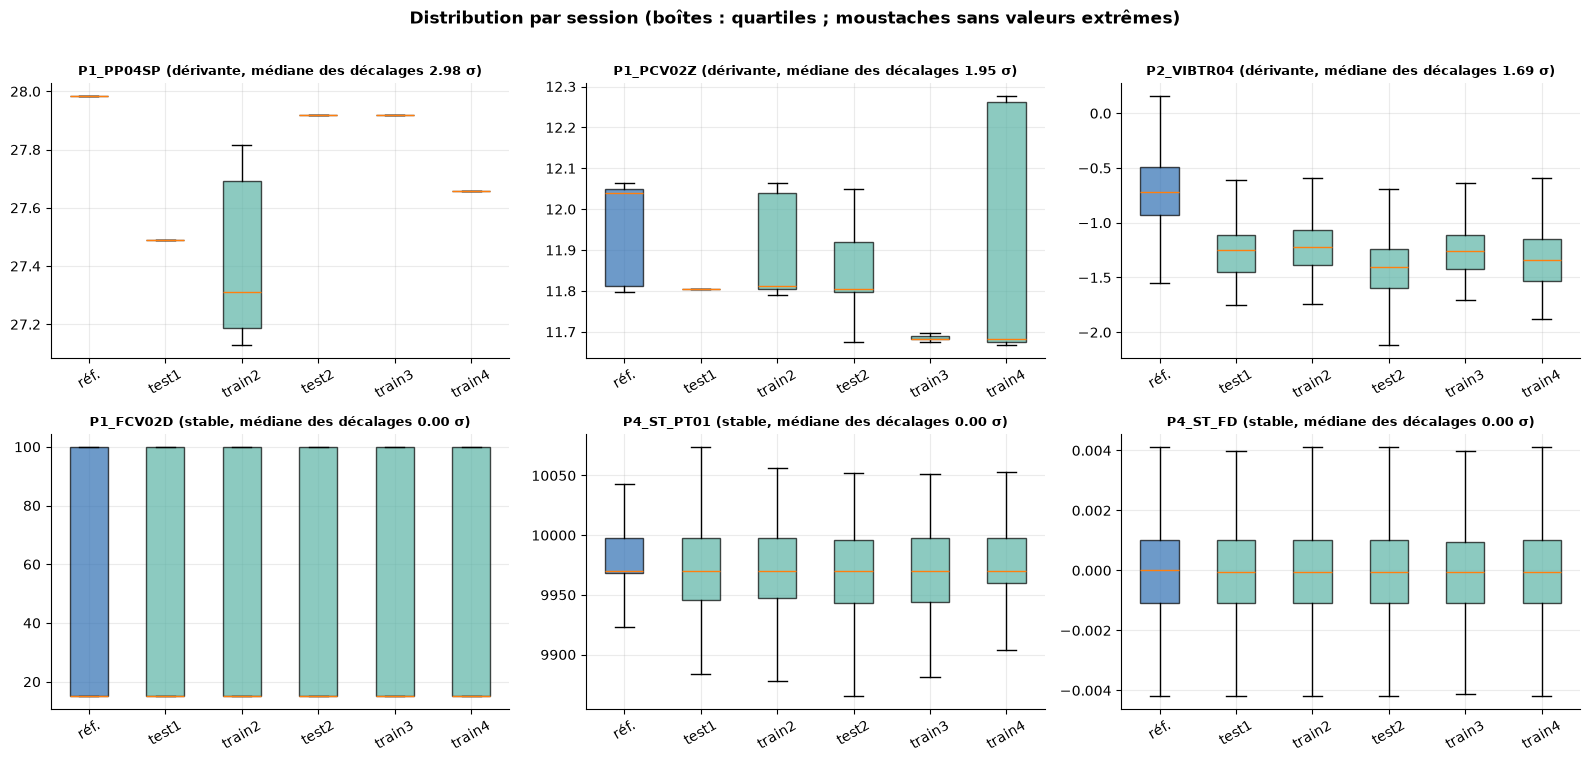

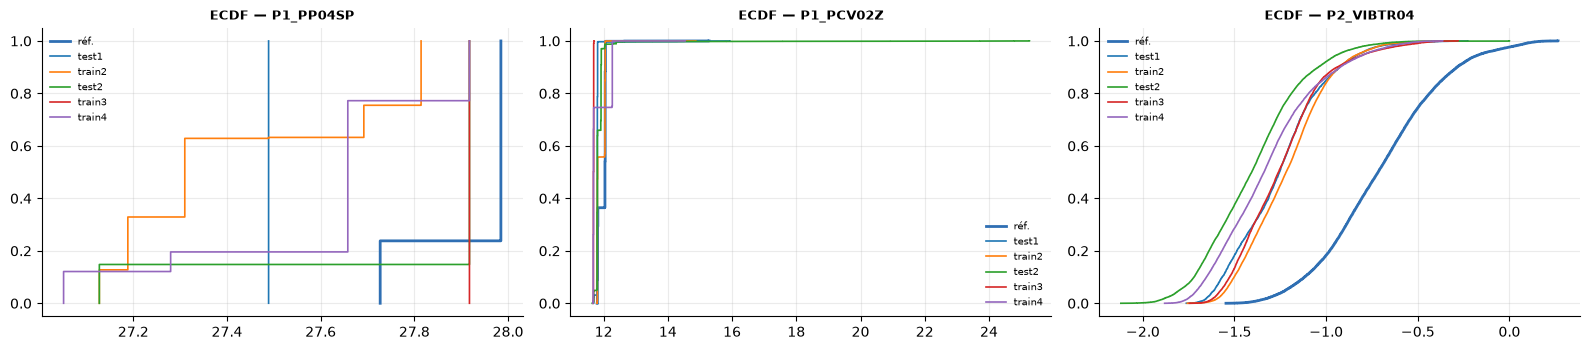

Variables les plus dérivantes :
  P1_PP04SP: 2.98 σ
  P1_PCV02Z: 1.95 σ
  P2_VIBTR04: 1.69 σ

Variables les plus stables :
  P1_FCV02D: 0.00 σ
  P4_ST_PT01: 0.00 σ
  P4_ST_FD: 0.00 σ
💡 [Distributions] Variables les plus dérivantes (médiane du décalage de session, en σ de référence) : P1_PP04SP (2.98 σ), P1_PCV02Z (1.95 σ), P2_VIBTR04 (1.69 σ) ; les plus stables : P1_FCV02D (0.00 σ), P4_ST_PT01 (0.00 σ), P4_ST_FD (0.00 σ).


In [31]:

# ==========================================
# 1. Calcul des décalages entre sessions
# ==========================================

sess_shift = pd.DataFrame({
    k: {
        c: abs(
            (clean[k][c].median() - REF_DF[c].median()) / REFS[c].std
        ) if REFS[c].std > 0 else np.nan
        for c in FEATS
    }
    for k in ORDER if ROLE[k] != "référence"
})

# Variables continues uniquement
cont = [c for c in FEATS if not REFS[c].discrete]

rank = (
    sess_shift.loc[cont]
    .median(axis=1)
    .sort_values(ascending=False)
)

top3 = rank.index[:3].tolist()
low3 = rank.index[-3:].tolist()
SHOW = top3 + low3

# ==========================================
# 2. Boxplots par session
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
axes = axes.ravel()

for ax, c in zip(axes, SHOW):

    sessions = [k for k in ORDER if ROLE[k] != "référence"]

    data = (
        [REF_DF[c].iloc[::20].dropna().to_numpy()]
        + [clean[k][c].iloc[::20].dropna().to_numpy() for k in sessions]
    )

    labs = ["réf."] + sessions

    bp = ax.boxplot(
        data,
        tick_labels=labs,
        showfliers=False,
        patch_artist=True
    )

    for i, p in enumerate(bp["boxes"]):
        p.set(
            facecolor=PAL["ref"] if i == 0 else PAL["prod"],
            alpha=0.7
        )

    ax.set_title(
        f"{c} ({'dérivante' if c in top3 else 'stable'}, "
        f"médiane des décalages {rank[c]:.2f} σ)",
        fontsize=9
    )

    ax.tick_params(axis="x", rotation=30)

fig.suptitle(
    "Distribution par session (boîtes : quartiles ; moustaches sans valeurs extrêmes)",
    y=1.01,
    fontweight="bold"
)

plt.tight_layout()
savefig("70_distributions_par_session")


# ==========================================
# 3. ECDF des trois variables dérivantes
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))

for ax, c in zip(axes, top3):

    for k, col in [("réf.", PAL["ref"])] + [
        (k, None) for k in ORDER if ROLE[k] != "référence"
    ]:

        series = REF_DF[c] if k == "réf." else clean[k][c]

        v = np.sort(series.iloc[::10].dropna().to_numpy())

        if len(v) == 0:
            continue

        ax.step(
            v,
            np.arange(1, len(v) + 1) / len(v),
            where="post",
            lw=2 if k == "réf." else 1.2,
            color=col,
            label=k
        )

    ax.set_title(f"ECDF — {c}", fontsize=9)
    ax.legend(frameon=False, fontsize=7)

plt.tight_layout()
savefig("70b_ecdf_variables_derivantes")


# ==========================================
# 4. Résumé des résultats
# ==========================================

print("Variables les plus dérivantes :")
for c in top3:
    print(f"  {c}: {rank[c]:.2f} σ")

print("\nVariables les plus stables :")
for c in low3:
    print(f"  {c}: {rank[c]:.2f} σ")

insight(
    "Distributions",
    f"Variables les plus dérivantes (médiane du décalage de session, en σ de référence) : "
    f"{', '.join(f'{c} ({rank[c]:.2f} σ)' for c in top3)} ; "
    f"les plus stables : "
    f"{', '.join(f'{c} ({rank[c]:.2f} σ)' for c in low3)}."
)


## 56. Évolution des statistiques des features
**Pourquoi.** Suivre la **moyenne** et la **dispersion** fenêtre après fenêtre montre *quand* et *comment* le comportement change (rupture brutale, dérive lente, retour à la référence). La moyenne est exprimée en écarts-types de référence ; la dispersion en rapport à celle de la référence.

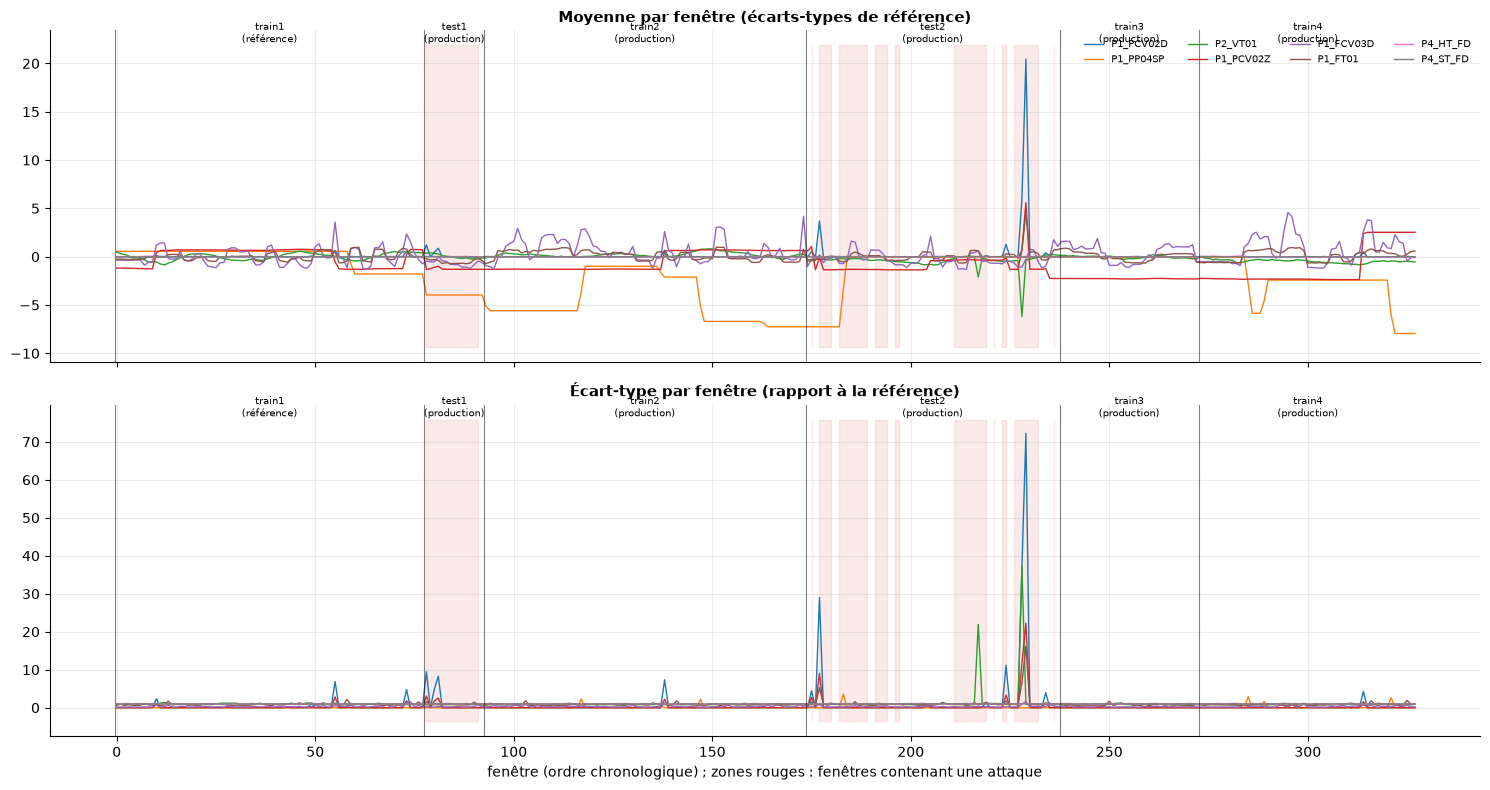

,écart max de la moyenne (σ),rapport médian des écarts-types,processus,rôle_probable
P1_PCV02D,20.44,0.00,P1 Chaudière,commande (demande)
P1_PP04SP,7.95,0.00,P1 Chaudière,consigne
P2_VT01,6.21,0.83,P2 Turbine,mesure (capteur)
P1_PCV02Z,5.59,0.02,P1 Chaudière,retour de position
P1_FCV03D,4.57,0.22,P1 Chaudière,commande (demande)
P1_FT01,4.53,0.81,P1 Chaudière,mesure (capteur)
P1_FCV03Z,4.53,0.23,P1 Chaudière,retour de position
P2_SCST,3.42,0.89,P2 Turbine,autre / non classé
P2_VIBTR04,3.17,0.59,P2 Turbine,autre / non classé
P1_LCV01Z,2.70,0.85,P1 Chaudière,retour de position


💡 [Évolution] 44 variables sur 66 voient leur moyenne s'écarter de plus de 1 σ de la référence dans au moins une fenêtre de production ; 24 voient leur dispersion changer de plus de 50 % (médiane).


In [32]:
M = np.array([w["data"].mean(axis=0) for w in windows]); S = np.array([w["data"].std(axis=0) for w in windows])
muR = np.array([REF_DF[c].mean() for c in FEATS]); sdR = np.array([REFS[c].std for c in FEATS]); Z = (M - muR) / sdR; SR = S / sdR
prodmask = (W.role != "référence").to_numpy(); span = pd.Series(np.nanmax(np.abs(Z[prodmask]), axis=0), index=FEATS).sort_values(ascending=False); pick = span.index[:6].tolist() + span.index[-2:].tolist()
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, arr, ttl in ((axes[0], Z, "Moyenne par fenêtre (écarts-types de référence)"), (axes[1], SR, "Écart-type par fenêtre (rapport à la référence)")):
    for c in pick: ax.plot(W.idx, arr[:, FEATS.index(c)], lw=1, label=c)
    for k in ORDER:
        sel = W[W.session == k]; ax.axvline(sel.idx.min() - .5, color="k", lw=.8, alpha=.5); ax.text(sel.idx.mean(), ax.get_ylim()[1], f"{k}\n({ROLE[k].split()[0]})", ha="center", va="bottom", fontsize=7)
    ax.fill_between(W.idx, ax.get_ylim()[0], ax.get_ylim()[1], where=(W.attack_frac > 0).to_numpy(), color=PAL["attack"], alpha=.12, step="mid"); ax.set_title(ttl)
axes[0].legend(frameon=False, ncol=4, fontsize=7); axes[1].set_xlabel("fenêtre (ordre chronologique) ; zones rouges : fenêtres contenant une attaque"); savefig("71_evolution_statistiques")
stab = pd.DataFrame({"écart max de la moyenne (σ)": np.nanmax(np.abs(Z[prodmask]), axis=0), "rapport médian des écarts-types": np.nanmedian(SR[prodmask], axis=0)}, index=FEATS).join(INFO[["processus", "rôle_probable"]]); display(stab.sort_values("écart max de la moyenne (σ)", ascending=False).head(10).round(2))
insight("Évolution", f"{int((stab['écart max de la moyenne (σ)'] > 1).sum())} variables sur {len(FEATS)} voient leur moyenne s'écarter de plus de 1 σ de la référence dans au moins une fenêtre de production ; {int((stab['rapport médian des écarts-types'].sub(1).abs() > .5).sum())} voient leur dispersion changer de plus de 50 % (médiane).")

## 57. Population Stability Index (PSI)
**Pourquoi.** C'est la mesure de drift la plus répandue en MLOps. On l'évalue sur chaque fenêtre de **production normale**, et on la compare à la fluctuation d'une fenêtre **de référence** (seuil nul).

Fenêtres de production analysées : 197
Nombre de mesures : 13002


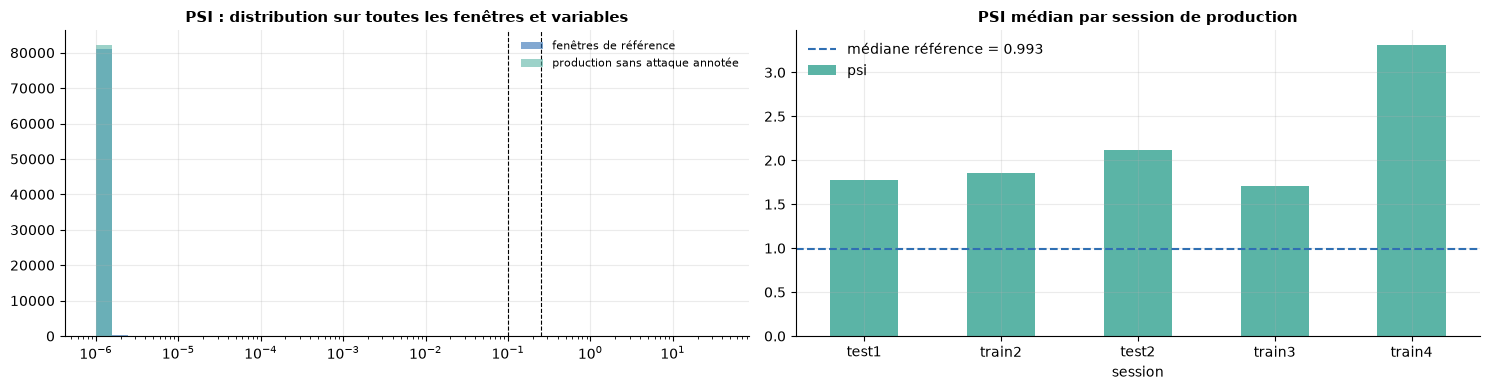

,PSI > 0.1,PSI > 0.25,PSI > seuil nul (p95)
session,,,
test1,82 %,70 %,9 %
train2,80 %,70 %,14 %
test2,82 %,72 %,17 %
train3,80 %,67 %,14 %
train4,84 %,75 %,24 %


,PSI médian,processus
feature,,
P4_HT_PS,35.236,P4 Simulation HIL
P2_ManualSD,34.969,P2 Turbine
x1003_18_SETPOINT_OUT,17.728,Contrôleurs DCS (x100x)
P1_PCV02Z,16.867,P1 Chaudière
P2_SCO,16.373,P2 Turbine
x1001_05_SETPOINT_OUT,16.323,Contrôleurs DCS (x100x)
x1002_08_SETPOINT_OUT,16.295,Contrôleurs DCS (x100x)
x1002_07_SETPOINT_OUT,16.117,Contrôleurs DCS (x100x)
P2_AutoSD,16.065,P2 Turbine


💡 [PSI] Sur les fenêtres de production analysées, 81 % des couples (fenêtre, variable) dépassent le seuil conventionnel de 0.1 et 71 % celui de 0.25, contre 76 % et 64 % sur les fenêtres de référence. Les seuils conventionnels doivent être interprétés avec prudence ; le seuil nul propre à chaque variable permet une comparaison mieux adaptée aux données.


In [34]:

# ==========================================
# 1. Construire les fenêtres de production
#    sans attaque annotée
# ==========================================

NORMAL_PROD = pd.concat(
    [NORMAL_TEST, NORMAL_TRAIN],
    ignore_index=True
)

print("Fenêtres de production analysées :", NORMAL_PROD["window"].nunique())
print("Nombre de mesures :", len(NORMAL_PROD))

# ==========================================
# 2. Fonction de visualisation des métriques
# ==========================================

def metric_panel(m, label, conv=None, logx=True, name=None):

    fig, ax = plt.subplots(1, 2, figsize=(15, 4))

    a = REFW[m].dropna().clip(lower=1e-6)
    b = NORMAL_PROD[m].dropna().clip(lower=1e-6)

    if len(a) == 0 or len(b) == 0:
        print(f"Données insuffisantes pour la métrique {m}")
        return

    xmin = min(a.min(), b.min())
    xmax = max(a.max(), b.max())

    if xmin == xmax:
        xmax = xmin * 10

    bins = np.logspace(
        np.log10(xmin),
        np.log10(xmax),
        40
    )

    # Distribution des métriques
    ax[0].hist(
        a, bins=bins, alpha=0.6,
        color=PAL["ref"], density=True,
        label="fenêtres de référence"
    )

    ax[0].hist(
        b, bins=bins, alpha=0.6,
        color=PAL["prod"], density=True,
        label="production sans attaque annotée"
    )

    for v in (conv or []):
        ax[0].axvline(v, ls="--", c="k", lw=0.8)

    if logx:
        ax[0].set_xscale("log")

    ax[0].set_title(
        f"{label} : distribution sur toutes les fenêtres et variables"
    )
    ax[0].legend(frameon=False, fontsize=8)

    # Médiane par session
    per = (
        NORMAL_PROD.groupby("session")[m]
        .median()
        .reindex([k for k in ORDER if ROLE[k] != "référence"])
    )

    ref_med = REFW[m].median()

    per.plot.bar(
        ax=ax[1],
        color=PAL["prod"],
        rot=0
    )

    ax[1].axhline(
        ref_med,
        color=PAL["ref"],
        ls="--",
        label=f"médiane référence = {ref_med:.3g}"
    )

    ax[1].set_title(
        f"{label} médian par session de production"
    )
    ax[1].legend(frameon=False)

    plt.tight_layout()
    savefig(name)


# ==========================================
# 3. Analyse PSI
# ==========================================

metric_panel(
    "psi",
    "PSI",
    conv=[PSI_MOD, PSI_STRONG],
    name="72_psi"
)

# ==========================================
# 4. Pourcentage de dépassement des seuils
# ==========================================

rows = []

for k in [k for k in ORDER if ROLE[k] != "référence"]:

    d = NORMAL_PROD[NORMAL_PROD.session == k]

    if len(d):

        rows.append({
            "session": k,
            f"PSI > {PSI_MOD}": f"{100 * (d.psi > PSI_MOD).mean():.0f} %",
            f"PSI > {PSI_STRONG}": f"{100 * (d.psi > PSI_STRONG).mean():.0f} %",
            "PSI > seuil nul (p95)": f"{100 * d['psi_>nul'].mean():.0f} %"
        })

display(pd.DataFrame(rows).set_index("session"))

# ==========================================
# 5. Variables présentant le PSI médian le plus élevé
# ==========================================

top_psi = (
    NORMAL_PROD.groupby("feature")["psi"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)

display(
    pd.DataFrame({"PSI médian": top_psi})
    .round(3)
    .join(INFO[["processus"]])
)

# ==========================================
# 6. Conclusion automatique
# ==========================================

insight(
    "PSI",
    f"Sur les fenêtres de production analysées, "
    f"{100 * (NORMAL_PROD.psi > PSI_MOD).mean():.0f} % "
    f"des couples (fenêtre, variable) dépassent le seuil "
    f"conventionnel de {PSI_MOD} et "
    f"{100 * (NORMAL_PROD.psi > PSI_STRONG).mean():.0f} % "
    f"celui de {PSI_STRONG}, contre "
    f"{100 * (REFW.psi > PSI_MOD).mean():.0f} % et "
    f"{100 * (REFW.psi > PSI_STRONG).mean():.0f} % "
    f"sur les fenêtres de référence. "
    f"Les seuils conventionnels doivent être interprétés "
    f"avec prudence ; le seuil nul propre à chaque variable "
    f"permet une comparaison mieux adaptée aux données."
)


## 58. Kolmogorov-Smirnov
**Pourquoi.** Le KS donne un écart (la statistique **D**) *et* une p-value. Sur ~10⁴ points et des signaux très autocorrélés, la p-value est **systématiquement ridicule** : elle ne mesure plus la dérive mais la taille de l'échantillon. On le démontre ci-dessous : même les fenêtres de la **référence** sont « significativement » différentes de la référence.

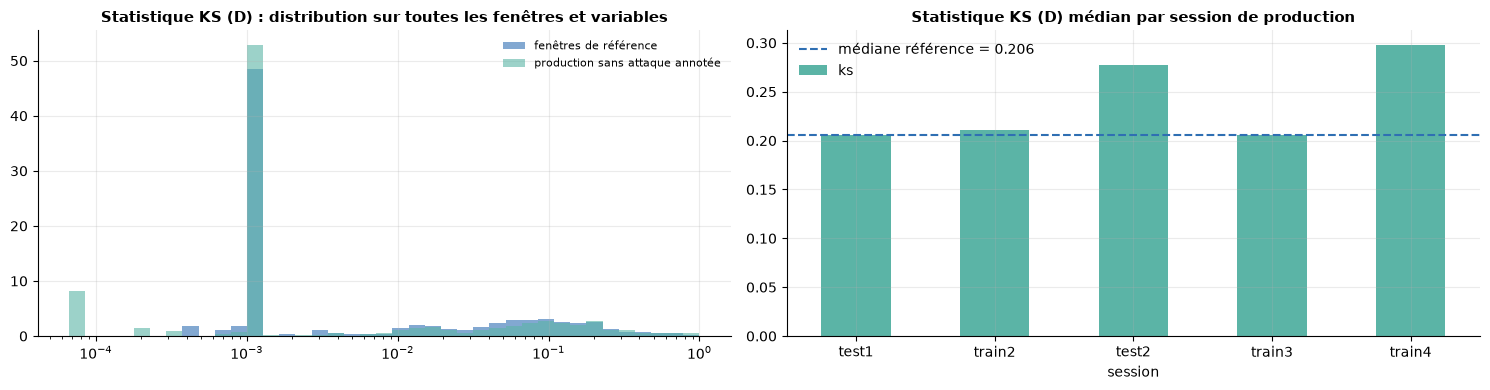

,fenêtres de référence,production normale
"part avec p < 0,001",94 %,95 %
D médiane,0.2057,0.233806


💡 [KS] Part des (fenêtre, variable) avec p < 0,001 : 94 % pour des fenêtres de la RÉFÉRENCE elle-même contre 95 % en production normale. Quand la p-value est quasi toujours « significative », elle ne discrimine plus rien : on s'appuie sur la taille d'effet (D, Wasserstein) et sur le seuil nul.


In [35]:
metric_panel("ks", "Statistique KS (D)", name="73_ks")
sig_ref, sig_prod = (REFW.ks_p < .001).mean(), (NORMAL_PROD.ks_p < .001).mean()
display(pd.DataFrame({"fenêtres de référence": {"part avec p < 0,001": f"{100*sig_ref:.0f} %", "D médiane": REFW.ks.median()}, "production normale": {"part avec p < 0,001": f"{100*sig_prod:.0f} %", "D médiane": NORMAL_PROD.ks.median()}}))
insight("KS", f"Part des (fenêtre, variable) avec p < 0,001 : {100*sig_ref:.0f} % pour des fenêtres de la RÉFÉRENCE elle-même contre {100*sig_prod:.0f} % en production normale. Quand la p-value est quasi toujours « significative », elle ne discrimine plus rien : on s'appuie sur la taille d'effet (D, Wasserstein) et sur le seuil nul.")

## 59. Distance de Wasserstein (normalisée)
**Pourquoi.** C'est la mesure la plus **lisible** : normalisée par l'écart-type de référence, elle s'exprime en « écarts-types de décalage ». Une valeur de 0,3 signifie que la distribution a glissé d'environ 0,3 σ.

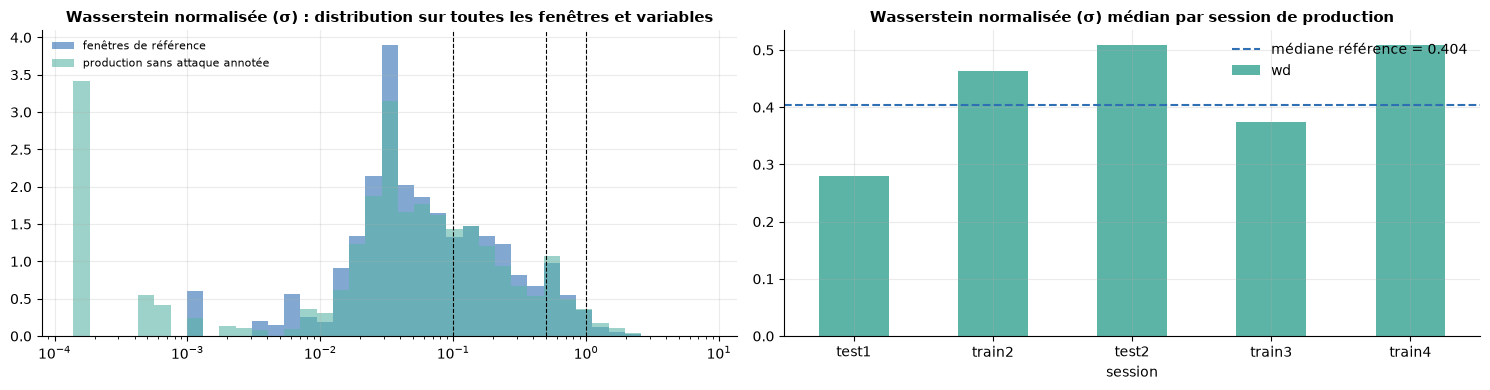

,fenêtres de référence,production normale
count,5148.000,13002.000
mean,0.500,0.619
std,0.446,0.686
min,0.001,0.000
50%,0.404,0.496
95%,1.366,1.820
max,3.596,7.962


💡 [Wasserstein] Décalage médian : 0.40 σ sur les fenêtres de référence (fluctuation normale) et 0.50 σ en production normale ; 95ᵉ centile 1.37 σ contre 1.82 σ. Le décalage médian de production vaut 1.2 × celui de la référence : la production normale reste dans l'ordre de grandeur de la fluctuation de la référence.


In [36]:
metric_panel("wd", "Wasserstein normalisée (σ)", conv=[.1, .5, 1.0], name="74_wasserstein")
display(pd.DataFrame({"fenêtres de référence": REFW.wd.describe(percentiles=[.5, .95]), "production normale": NORMAL_PROD.wd.describe(percentiles=[.5, .95])}).round(3))
insight("Wasserstein", f"Décalage médian : {REFW.wd.median():.2f} σ sur les fenêtres de référence (fluctuation normale) et {NORMAL_PROD.wd.median():.2f} σ en production normale ; 95ᵉ centile {REFW.wd.quantile(.95):.2f} σ contre {NORMAL_PROD.wd.quantile(.95):.2f} σ. Le décalage médian de production vaut {NORMAL_PROD.wd.median()/max(REFW.wd.median(),1e-9):.1f} × celui de la référence : " + ("la production normale s'écarte nettement plus de la référence qu'une fenêtre de la référence elle-même." if NORMAL_PROD.wd.median() > 1.5 * REFW.wd.median() else "la production normale reste dans l'ordre de grandeur de la fluctuation de la référence."))

## 60. Jensen-Shannon
**Pourquoi.** Divergence symétrique et bornée (0 à 1) : utile pour **comparer des variables d'échelles et de natures différentes** (continues et binaires) sur une même échelle.

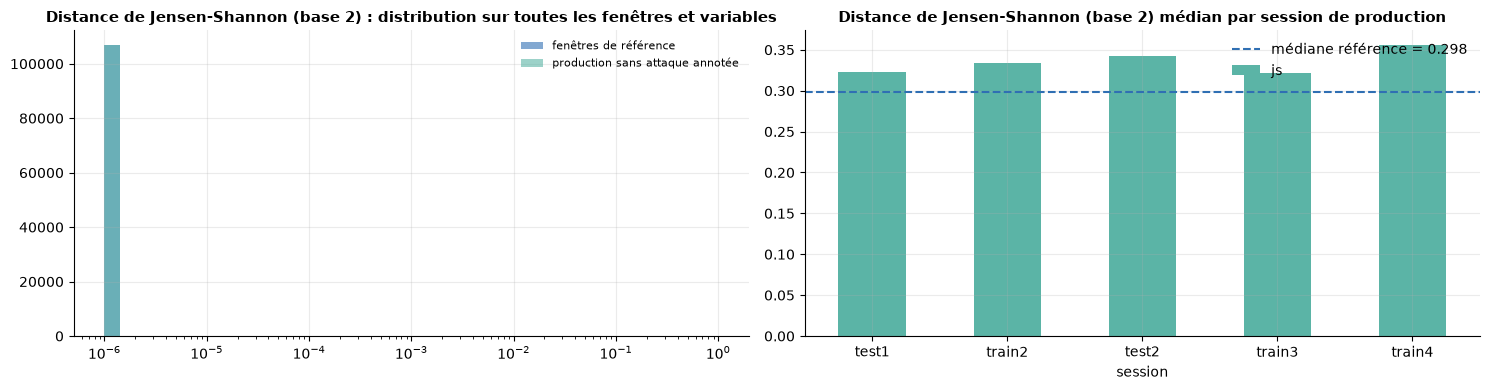

💡 [Jensen-Shannon] Distance médiane : 0.298 (référence) contre 0.334 (production normale) ; 20 % des couples (fenêtre, variable) de production normale dépassent le seuil nul de leur variable.


In [37]:
metric_panel("js", "Distance de Jensen-Shannon (base 2)", name="75_js")
insight("Jensen-Shannon", f"Distance médiane : {REFW.js.median():.3f} (référence) contre {NORMAL_PROD.js.median():.3f} (production normale) ; {100*NORMAL_PROD['js_>nul'].mean():.0f} % des couples (fenêtre, variable) de production normale dépassent le seuil nul de leur variable.")

## 61. Analyse du drift par feature
**Pourquoi.** Passer de « la plupart des variables dérivent » à **« lesquelles, et de quelle façon »**. On résume, par variable, les quatre mesures sur les fenêtres de production normales, on les classe par **rang consensuel** (moyenne des rangs), et on vérifie que les mesures **s'accordent**.

,psi_med,ks_med,wd_med,js_med,wd_p95,au_dessus_nul,rang_consensuel,processus,type_physique,rôle_probable
feature,,,,,,,,,,
P1_PCV02Z,16.867,0.908,1.366,0.862,2.532,0.624,3.750,P1 Chaudière,Vanne / actionneur,retour de position
x1003_18_SETPOINT_OUT,17.728,0.839,1.197,0.893,1.938,0.076,4.000,Contrôleurs DCS (x100x),Autre / non classé,consigne
x1002_08_SETPOINT_OUT,16.295,0.800,1.219,0.857,1.774,0.046,5.500,Contrôleurs DCS (x100x),Autre / non classé,consigne
P4_ST_PS,14.758,0.770,1.216,0.792,2.053,0.000,7.750,P4 Simulation HIL,Simulateur HIL,état / simulateur
P4_HT_PS,35.236,0.703,0.886,1.000,1.454,0.000,7.875,P4 Simulation HIL,Simulateur HIL,état / simulateur
x1002_07_SETPOINT_OUT,16.117,0.764,1.083,0.855,1.692,0.010,8.000,Contrôleurs DCS (x100x),Autre / non classé,consigne
x1001_05_SETPOINT_OUT,16.323,0.734,1.029,0.855,1.888,0.127,8.500,Contrôleurs DCS (x100x),Autre / non classé,consigne
P1_FT03Z,13.039,0.735,1.140,0.783,1.742,0.051,9.500,P1 Chaudière,Débit,retour de position
P2_VIBTR04,7.826,0.769,1.836,0.734,2.485,0.609,9.750,P2 Turbine,Autre / non classé,autre / non classé


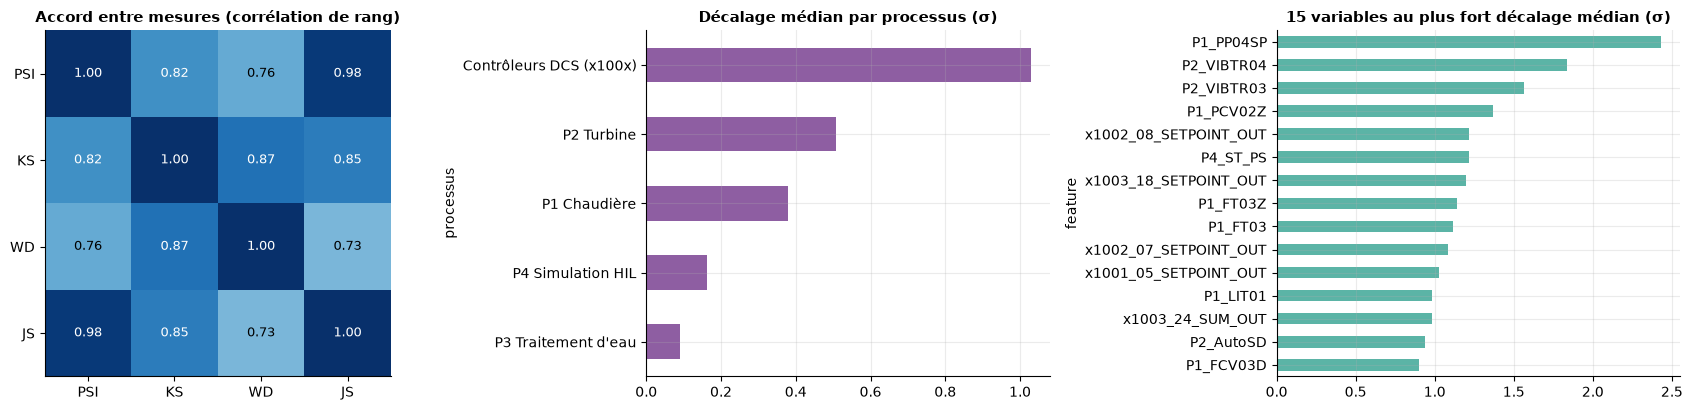

,wd_median,part_au_dessus_nul,variables
processus,,,
Contrôleurs DCS (x100x),1.029,0.080,7
P1 Chaudière,0.380,0.127,27
P2 Turbine,0.509,0.167,16
P3 Traitement d'eau,0.089,0.075,5
P4 Simulation HIL,0.162,0.107,11


💡 [Drift par feature] Accord moyen entre les 4 mesures (corrélation de rang des variables) : 0.84. Variables au plus fort drift consensuel : P1_PCV02Z, x1003_18_SETPOINT_OUT, x1002_08_SETPOINT_OUT, P4_ST_PS, P4_HT_PS. Processus au décalage médian le plus élevé : Contrôleurs DCS (x100x) (1.03 σ) ; le plus stable : P3 Traitement d'eau (0.09 σ).
💡 [Drift par feature] 6 % des variables dépassent leur seuil nul de Wasserstein dans plus de la moitié des fenêtres de production normales : la majorité des variables restent dans leur fluctuation normale ; le drift est concentré sur quelques variables.


In [38]:
agg = NORMAL_PROD.groupby("feature").agg(psi_med=("psi", "median"), ks_med=("ks", "median"), wd_med=("wd", "median"), js_med=("js", "median"), wd_p95=("wd", lambda s: s.quantile(.95)),
                                       au_dessus_nul=("wd_>nul", "mean"))
agg["rang_consensuel"] = agg[["psi_med", "ks_med", "wd_med", "js_med"]].rank(ascending=False).mean(axis=1); agg = agg.join(INFO[["processus", "type_physique", "rôle_probable"]]).sort_values("rang_consensuel"); display(agg.head(15).round(3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
cm = agg[["psi_med", "ks_med", "wd_med", "js_med"]].corr(method="spearman"); im = ax[0].imshow(cm, cmap="Blues", vmin=.5, vmax=1); ax[0].grid(False); ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["PSI", "KS", "WD", "JS"]); ax[0].set_yticks(range(4)); ax[0].set_yticklabels(["PSI", "KS", "WD", "JS"]); ax[0].set_title("Accord entre mesures (corrélation de rang)")
for i in range(4):
    for j in range(4): ax[0].text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if cm.iloc[i, j] > .8 else "black")
pp = agg.groupby("processus").agg(wd_median=("wd_med", "median"), part_au_dessus_nul=("au_dessus_nul", "mean"), variables=("wd_med", "size")); pp.sort_values("wd_median").wd_median.plot.barh(ax=ax[1], color=PAL["viol"]); ax[1].set_title("Décalage médian par processus (σ)")
agg.sort_values("wd_med").tail(15).wd_med.plot.barh(ax=ax[2], color=PAL["prod"]); ax[2].set_title("15 variables au plus fort décalage médian (σ)"); savefig("76_drift_par_feature"); display(pp.round(3))
EV["metric_agreement"] = float(cm.values[np.triu_indices(4, 1)].mean())
insight("Drift par feature", f"Accord moyen entre les 4 mesures (corrélation de rang des variables) : {EV['metric_agreement']:.2f}. Variables au plus fort drift consensuel : {', '.join(agg.index[:5])}. Processus au décalage médian le plus élevé : {pp.wd_median.idxmax()} ({pp.wd_median.max():.2f} σ) ; le plus stable : {pp.wd_median.idxmin()} ({pp.wd_median.min():.2f} σ).")
share_unstable = (agg.au_dessus_nul > .5).mean()
insight("Drift par feature", f"{100*share_unstable:.0f} % des variables dépassent leur seuil nul de Wasserstein dans plus de la moitié des fenêtres de production normales : " + ("le drift n'est pas un événement rare, c'est l'état habituel de la production." if share_unstable > .3 else "la majorité des variables restent dans leur fluctuation normale ; le drift est concentré sur quelques variables."))

## 62. Heatmap de drift
**Pourquoi.** Une seule image pour voir **où** (quelles variables, regroupées par processus) et **quand** (fenêtres dans l'ordre chronologique) le drift apparaît. La bande du haut indique la part d'attaque de chaque fenêtre (description seulement).

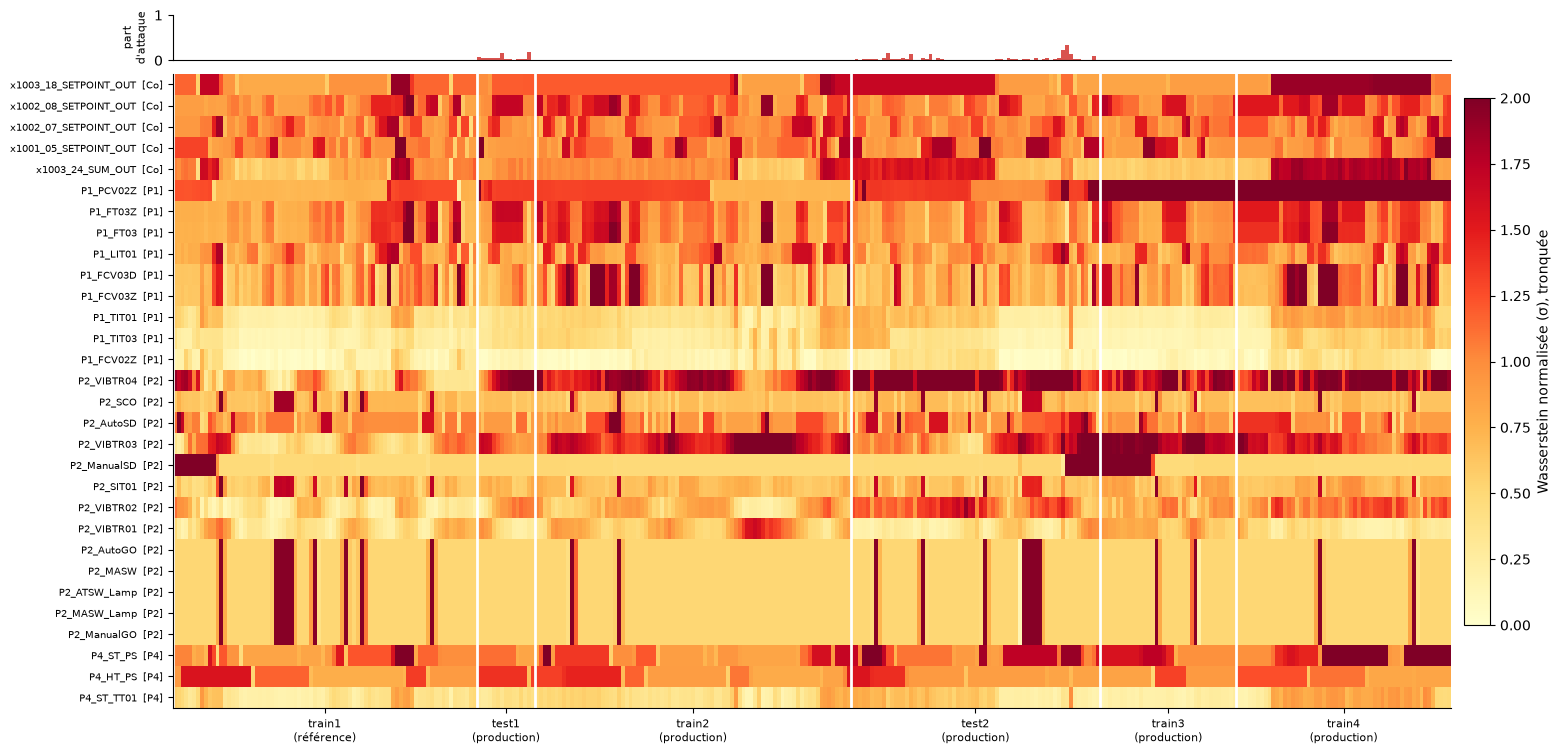

💡 [Heatmap] Décalage médian (σ) par session de production normale : test1 0.28, train2 0.46, test2 0.51, train3 0.37, train4 0.51. Part de la variance du drift de fenêtre expliquée par la session : η² = 0.26 (l'effet de session n'est pas dominant : une part importante du drift varie d'une heure à l'autre à l'intérieur d'une session).


In [40]:
top = agg.head(30).index.tolist(); order_rows = INFO.loc[top].assign(r=agg.loc[top, "rang_consensuel"]).sort_values(["processus", "r"]).index.tolist()
H = DRIFT.pivot(index="feature", columns="window", values="wd").reindex(index=order_rows, columns=W.window)
fig = plt.figure(figsize=(17, 9)); gs = fig.add_gridspec(2, 1, height_ratios=[1, 14], hspace=.04); a0, a1 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
a0.bar(W.idx, W.attack_frac, color=PAL["attack"], width=1); a0.set_xlim(-.5, len(W) - .5); a0.set_xticks([]); a0.set_yticks([0, 1]); a0.set_ylabel("part\nd'attaque", fontsize=8); a0.grid(False)
im = a1.imshow(H.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0, vmax=min(2, np.nanpercentile(H.to_numpy(), 98)), interpolation="nearest"); a1.grid(False); a1.set_yticks(range(len(order_rows))); a1.set_yticklabels([f"{c}  [{INFO.loc[c, 'processus'][:2]}]" for c in order_rows], fontsize=7)
mid = [W[W.session == k].idx.mean() for k in ORDER]; a1.set_xticks(mid); a1.set_xticklabels([f"{k}\n({ROLE[k].split()[0]})" for k in ORDER], fontsize=8)
for k in ORDER: a1.axvline(W[W.session == k].idx.min() - .5, color="white", lw=2)
plt.colorbar(im, ax=[a0, a1], fraction=.02, pad=.01, label="Wasserstein normalisée (σ), tronquée"); savefig("77_heatmap_drift")
prod_sessions = [k for k in ORDER if ROLE[k] != "référence"]; sess_med = NORMAL_PROD.groupby("session").wd.median().reindex(prod_sessions); no_normal = sess_med[sess_med.isna()].index.tolist(); sess_med = sess_med.dropna()
EV["session_median_wd"] = sess_med.round(3).to_dict()
wscore = NORMAL_PROD.groupby("window").agg(session=("session", "first"), wd=("wd", "median")); g = [v.wd.to_numpy() for _, v in wscore.groupby("session") if len(v) >= 2]
eta2 = float(1 - sum(((x - x.mean()) ** 2).sum() for x in g) / max(((np.concatenate(g) - np.concatenate(g).mean()) ** 2).sum(), 1e-12)) if len(g) >= 2 else float("nan"); EV["session_effect_eta2"] = eta2
insight("Heatmap", "Décalage médian (σ) par session de production normale : " + ", ".join(f"{k} {v:.2f}" for k, v in sess_med.items()) + (f" ; {', '.join(no_normal)} : aucune fenêtre sans attaque (toutes contiennent au moins une attaque), donc exclues de ce calcul" if no_normal else "") + (f". Part de la variance du drift de fenêtre expliquée par la session : η² = {eta2:.2f} " + ("(les motifs se lisent par COLONNES : une session entière change de régime, le drift est surtout un effet de session)." if eta2 > .5 else "(l'effet de session n'est pas dominant : une part importante du drift varie d'une heure à l'autre à l'intérieur d'une session).") if np.isfinite(eta2) else "."))

## 63. Comparaison du drift normal et du changement associé aux attaques
**Pourquoi.** Si le drift *normal* est aussi grand que le changement provoqué par une attaque, un détecteur de drift ne pourra jamais distinguer les deux, et le Decision Engine risque de réagir à du bruit.

**Méthode.** Pour chaque attaque, on mesure, variable par variable, la **distance de Wasserstein (en σ de référence)** entre la distribution *pendant* l'attaque et celle des **5 minutes normales qui la précèdent**. On compare à des **fenêtres normales de même durée** (placebo) mesurées de la même façon.

> **Usage des labels (anti-fuite).** Section purement *descriptive*. Les résultats de **test1** sont ceux qui peuvent éclairer une décision ; ceux de **test2** sont montrés en **lecture seule, pour vérifier la reproductibilité**, et ne doivent servir à retenir ou écarter aucune variable.

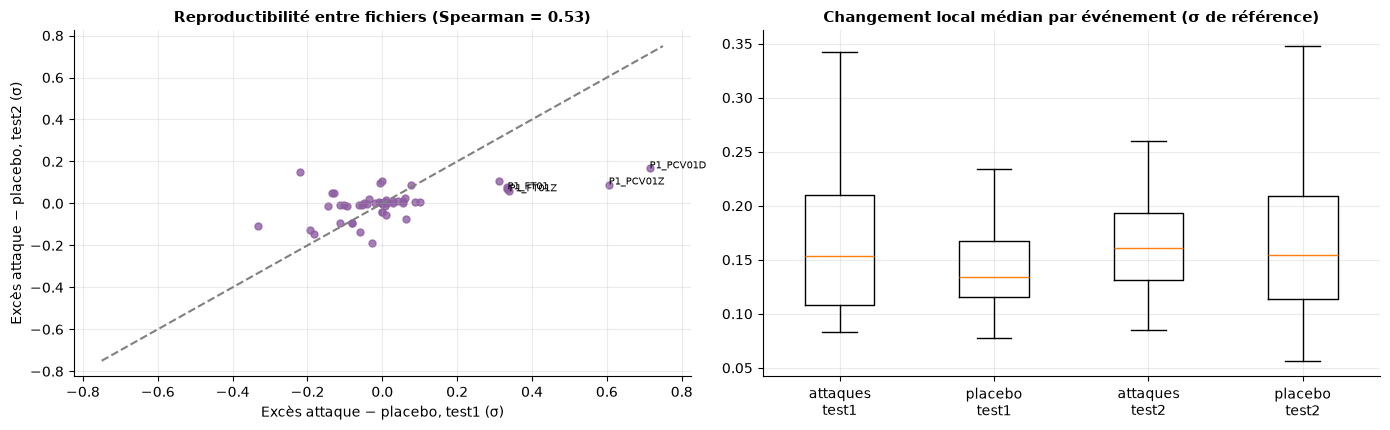

💡 [Drift vs attaques] Changement local médian pendant une attaque : 0.151 σ (test1), contre 0.167 σ (test2). Le drift naturel d'une fenêtre d'une heure en production sans attaque annotée est de 0.496 σ. Ces échelles temporelles étant différentes, la comparaison doit être interprétée avec prudence.
💡 [Drift vs attaques] 3 variable(s) présentent, dans plus de la moitié des attaques de test1, un changement supérieur au 95e centile du placebo. Reproductibilité du classement entre test1 et test2 (Spearman) : 0.53 — classement relativement stable.


,attaque_méd_test1,placebo_méd_test1,excès_test1,part_attaques>p95placebo_test1,attaque_méd_test2,placebo_méd_test2,excès_test2,part_attaques>p95placebo_test2,processus
P1_PCV01D,1.182,0.468,0.714,0.714,0.708,0.541,0.167,0.211,P1 Chaudière
P1_PCV01Z,1.080,0.475,0.605,0.500,0.646,0.556,0.090,0.211,P1 Chaudière
P1_FT01Z,0.897,0.557,0.340,0.286,0.553,0.495,0.058,0.263,P1 Chaudière
P1_FT01,0.886,0.552,0.334,0.286,0.555,0.488,0.067,0.263,P1 Chaudière
P1_LCV01Z,0.977,0.645,0.332,0.286,0.728,0.651,0.077,0.053,P1 Chaudière
P1_LCV01D,0.994,0.682,0.312,0.214,0.757,0.650,0.106,0.079,P1 Chaudière
P1_FT03Z,0.170,0.069,0.101,0.643,0.088,0.079,0.009,0.105,P1 Chaudière
P1_FT03,0.147,0.061,0.086,0.643,0.089,0.084,0.005,0.105,P1 Chaudière
P1_TIT03,0.513,0.437,0.076,0.071,0.451,0.363,0.088,0.053,P1 Chaudière
P1_PP04,0.311,0.249,0.062,0.357,0.136,0.210,-0.074,0.053,P1 Chaudière


,"changement pendant une attaque (médiane sur variables et attaques, σ)","changement placebo, mêmes durées (σ)","drift naturel d'une fenêtre d'1 h, production normale (σ)"
test1,0.151,0.167,0.496
test2,0.142,0.142,0.496


In [42]:

# ==========================================
# 1. Reproductibilité entre test1 et test2
# ==========================================

rep = LS[["excès_test1", "excès_test2"]].corr(
    method="spearman"
).iloc[0, 1]

EV["excess_replication_spearman"] = float(rep)

# ==========================================
# 2. Visualisations
# ==========================================

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))

# Graphique de reproductibilité
ax[0].scatter(
    LS["excès_test1"],
    LS["excès_test2"],
    s=25,
    color=PAL["viol"],
    alpha=0.8
)

lim = max(
    LS[["excès_test1", "excès_test2"]].abs().max()
) * 1.05

ax[0].plot(
    [-lim, lim],
    [-lim, lim],
    "--",
    c="grey"
)

ax[0].set_xlabel("Excès attaque − placebo, test1 (σ)")
ax[0].set_ylabel("Excès attaque − placebo, test2 (σ)")
ax[0].set_title(
    f"Reproductibilité entre fichiers "
    f"(Spearman = {rep:.2f})"
)

for t in LS["excès_test1"].sort_values(
    ascending=False
).head(4).index:

    ax[0].annotate(
        t,
        (
            LS.loc[t, "excès_test1"],
            LS.loc[t, "excès_test2"]
        ),
        fontsize=7
    )

# Comparaison attaques / placebos
box_data = [
    a1.median(axis=1),
    p1.median(axis=1),
    a2.median(axis=1),
    p2.median(axis=1)
]

ax[1].boxplot(
    box_data,
    tick_labels=[
        "attaques\ntest1",
        "placebo\ntest1",
        "attaques\ntest2",
        "placebo\ntest2"
    ],
    showfliers=False
)

ax[1].set_title(
    "Changement local médian par événement "
    "(σ de référence)"
)

plt.tight_layout()
savefig("78_drift_vs_attaques")

# ==========================================
# 3. Nombre de variables sensibles aux attaques
# ==========================================

sp = (
    LS["part_attaques>p95placebo_test1"] > 0.5
).sum()

# ==========================================
# 4. Conclusions
# ==========================================

insight(
    "Drift vs attaques",
    f"Changement local médian pendant une attaque : "
    f"{cmp.iloc[0,0]:.3f} σ (test1), contre "
    f"{cmp.iloc[0,1]:.3f} σ (test2). "
    f"Le drift naturel d'une fenêtre d'une heure en production "
    f"sans attaque annotée est de {nat_prod:.3f} σ. "
    f"Ces échelles temporelles étant différentes, "
    f"la comparaison doit être interprétée avec prudence."
)

insight(
    "Drift vs attaques",
    f"{sp} variable(s) présentent, dans plus de la moitié "
    f"des attaques de test1, un changement supérieur au "
    f"95e centile du placebo. "
    f"Reproductibilité du classement entre test1 et test2 "
    f"(Spearman) : {rep:.2f} "
    + (
        "— classement relativement stable."
        if rep > 0.5
        else "— classement peu reproductible : prudence dans "
             "le choix des variables."
    )
)

display(
    LS.sort_values(
        "excès_test1",
        ascending=False
    ).head(12).round(3).join(INFO[["processus"]])
)

display(cmp.round(3))


In [43]:
REF_DF = pd.concat([clean[k] for k in REF_FILES], ignore_index=True)
FEATS = [c for c in sensor_columns(REF_DF) if REF_DF[c].std() > 0]; CONST = [c for c in sensor_columns(REF_DF) if REF_DF[c].std() == 0]
REFS = {c: DR.RefDist(REF_DF[c].to_numpy(), bins=BINS, seed=SEED) for c in FEATS}; INFO = pd.DataFrame([{"tag": c, **T.tag_info(c)} for c in FEATS]).set_index("tag")
ROLE = {k: ("référence" if k in REF_FILES else "production + attaques" if "label" in clean[k] else "production normale") for k in ORDER}
roles = pd.DataFrame({k: {"rôle": ROLE[k], "début": clean[k].timestamp.min(), "fin": clean[k].timestamp.max(), "heures": round(len(clean[k]) / 3600, 1), "% attaque": round(100 * clean[k].label.mean(), 2) if "label" in clean[k] else 0.0} for k in ORDER}).T
display(roles)
n_disc = sum(REFS[c].discrete for c in FEATS)
insight("Référence", f"Référence : {' + '.join(REF_FILES)} = {len(REF_DF)/3600:.0f} h, {len(FEATS)} variables non constantes ({n_disc} binaires/discrètes traitées par catégories, {len(FEATS)-n_disc} continues par déciles) ; {len(CONST)} variables constantes écartées de l'analyse de distribution.")

,rôle,début,fin,heures,% attaque
train1,référence,2022-08-04 18:00:01,2022-08-08 00:00:00,78.0,0.0
test1,production + attaques,2022-08-12 16:00:01,2022-08-13 07:00:00,15.0,5.52
train2,production normale,2022-08-13 07:00:01,2022-08-16 16:00:00,81.0,0.0
test2,production + attaques,2022-08-17 00:00:01,2022-08-19 16:00:00,64.0,3.65
train3,production normale,2022-08-19 16:00:01,2022-08-21 03:00:00,35.0,0.0
train4,production normale,2022-08-22 17:00:01,2022-08-25 00:00:00,55.0,0.0


💡 [Référence] Référence : train1 = 78 h, 66 variables non constantes (8 binaires/discrètes traitées par catégories, 58 continues par déciles) ; 20 variables constantes écartées de l'analyse de distribution.


## 64. Identification des features instables
**Pourquoi.** Pour le monitoring MLOps, chaque variable relève d'une de quatre situations selon deux critères :
- **stabilité** : fraction des fenêtres de production *normales* où son décalage dépasse son seuil nul (jamais mesurée avec des labels) ;
- **sensibilité aux attaques** : excès de changement local en attaque par rapport au placebo (**test1 seulement** pour décider).

| | Sensible aux attaques | Peu sensible aux attaques |
|---|---|---|
| **Stable** | **à privilégier pour la détection** | à surveiller (peu utile) |
| **Instable** | **ambiguë** : bruit de drift mêlé au signal ; à normaliser ou à croiser avec d'autres | **candidate à l'exclusion ou à la normalisation par session** |

> Les seuils de découpage sont **relatifs** (médianes des deux axes) : ils classent les variables entre elles ; ils ne définissent pas une valeur « acceptable » absolue.

,variables
famille,
stable et peu sensible,25
instable et peu sensible (à normaliser / exclure),18
instable et sensible (ambiguë),13
stable et sensible,10


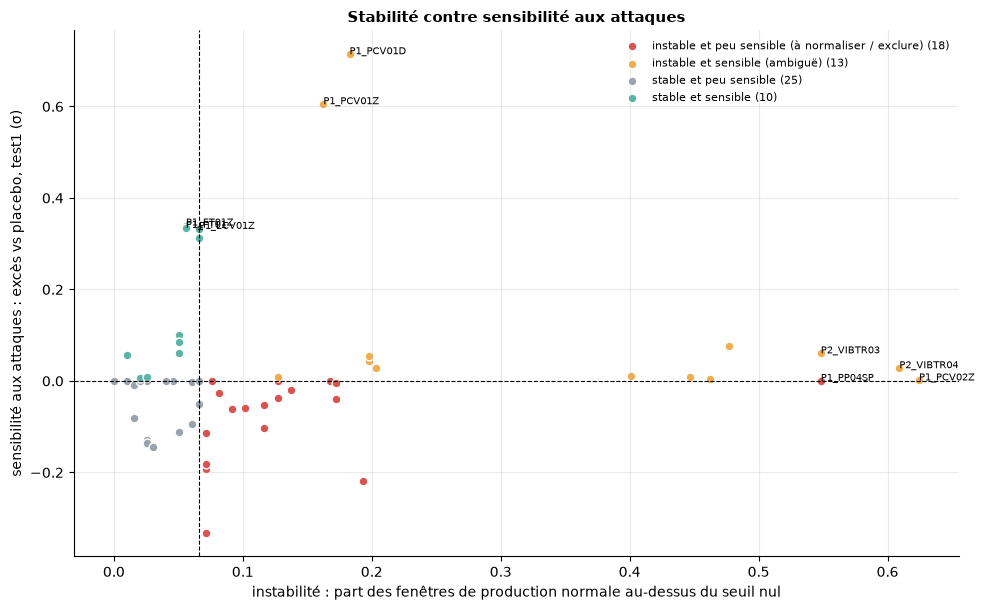

stable et sensible : ['P1_FT01Z', 'P1_FT01', 'P1_LCV01Z', 'P1_LCV01D', 'P1_FT03Z', 'P1_FT03', 'P1_PP04', 'P1_LIT01', 'P1_TIT02', 'P1_FCV02Z']
instable et sensible (ambiguë) : ['P1_PCV01D', 'P1_PCV01Z', 'P1_TIT03', 'P2_VIBTR03', 'P1_FCV03Z', 'P1_FCV03D', 'P2_VT01', 'P2_VIBTR04', 'P4_HT_FD', 'P2_VIBTR01']
instable et peu sensible (à normaliser / exclure) : ['x1003_18_SETPOINT_OUT', 'x1001_05_SETPOINT_OUT', 'P1_PP04SP', 'P1_TIT01', 'P4_ST_TT01', 'P4_ST_FD', 'P3_LCP01D', 'P1_PIT01', 'x1003_24_SUM_OUT', 'P4_ST_PT01']


In [44]:
Q = agg[["au_dessus_nul", "wd_med", "wd_p95"]].rename(columns={"au_dessus_nul": "instabilité", "wd_med": "drift_med_σ", "wd_p95": "drift_p95_σ"}).join(LS[["excès_test1", "excès_test2", "part_attaques>p95placebo_test1"]]).join(INFO[["processus", "type_physique", "rôle_probable"]])
tx, ty = Q["instabilité"].median(), Q["excès_test1"].median()
Q["famille"] = np.select([(Q.instabilité <= tx) & (Q.excès_test1 > ty), (Q.instabilité > tx) & (Q.excès_test1 > ty), (Q.instabilité > tx) & (Q.excès_test1 <= ty)], ["stable et sensible", "instable et sensible (ambiguë)", "instable et peu sensible (à normaliser / exclure)"], "stable et peu sensible")
Q.to_csv(REPORT_DIR / "drift_feature_stability.csv"); display(Q.famille.value_counts().to_frame("variables"))
fig, ax = plt.subplots(figsize=(10, 6.2)); colors = {"stable et sensible": PAL["prod"], "instable et sensible (ambiguë)": PAL["warn"], "instable et peu sensible (à normaliser / exclure)": PAL["attack"], "stable et peu sensible": PAL["grey"]}
for f, g in Q.groupby("famille"): ax.scatter(g.instabilité, g.excès_test1, s=40, color=colors[f], label=f"{f} ({len(g)})", edgecolor="white")
ax.axvline(tx, ls="--", c="k", lw=.8); ax.axhline(ty, ls="--", c="k", lw=.8)
for t in Q.sort_values("excès_test1", ascending=False).head(5).index.tolist() + Q.sort_values("instabilité", ascending=False).head(4).index.tolist(): ax.annotate(t, (Q.loc[t, "instabilité"], Q.loc[t, "excès_test1"]), fontsize=7)
ax.set_xlabel("instabilité : part des fenêtres de production normale au-dessus du seuil nul"); ax.set_ylabel("sensibilité aux attaques : excès vs placebo, test1 (σ)"); ax.legend(frameon=False, fontsize=8, loc="best"); ax.set_title("Stabilité contre sensibilité aux attaques"); savefig("79_features_stabilite")
for f in ["stable et sensible", "instable et sensible (ambiguë)", "instable et peu sensible (à normaliser / exclure)"]: print(f"{f} :", Q[Q.famille == f].sort_values("excès_test1", ascending=False).index.tolist()[:10])

,fenêtres,score médian,score max,part d'alarmes (score > seuil global)
fenêtres de référence,78.0,0.015,0.333,5 %
production normale,197.0,0.106,0.394,11 %
production avec attaque,53.0,0.106,0.258,4 %


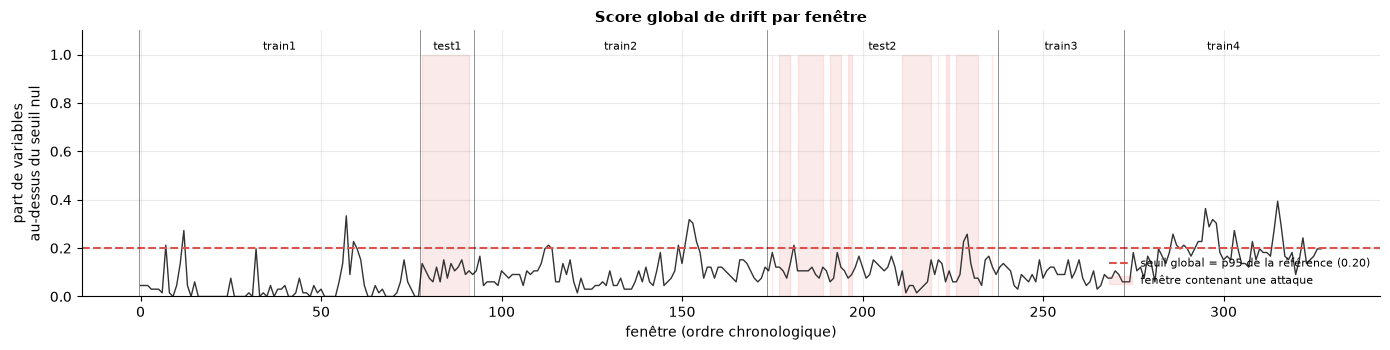

💡 [Détecteur naïf] Un score global (part de variables au-dessus de leur seuil nul) calé sur le 95ᵉ centile de la référence (0.20) déclencherait une alarme sur 11 % des fenêtres de production NORMALES : ce taux représente plusieurs fois le taux nominal de 5 %. Un drift détecté seul ne peut PAS déclencher un réentraînement, ni même une alerte opérateur.


In [45]:
# --- Un détecteur de drift « global » naïf serait-il utilisable ? ---
gs = DRIFT.groupby("window").agg(session=("session", "first"), role=("role", "first"), attack_frac=("attack_frac", "first"), score=("wd_>nul", "mean")); gs["idx"] = W.set_index("window").idx; gs = gs.sort_values("idx")
thr_global = gs[gs.role == "référence"].score.quantile(NULL_Q)
rate = pd.DataFrame({"fenêtres de référence": gs[gs.role == "référence"].score, "production normale": gs[(gs.role != "référence") & (gs.attack_frac == 0)].score, "production avec attaque": gs[(gs.role != "référence") & (gs.attack_frac > 0)].score}).describe().T[["count", "50%", "max"]]
rate["part d'alarmes (score > seuil global)"] = [f"{100*(gs[(gs.role == 'référence')].score > thr_global).mean():.0f} %", f"{100*(gs[(gs.role != 'référence') & (gs.attack_frac == 0)].score > thr_global).mean():.0f} %", f"{100*(gs[(gs.role != 'référence') & (gs.attack_frac > 0)].score > thr_global).mean():.0f} %"]
display(rate.rename(columns={"count": "fenêtres", "50%": "score médian", "max": "score max"}).round(3))
fig, ax = plt.subplots(figsize=(14, 3.6)); ax.plot(gs.idx, gs.score, color="#333", lw=1); ax.axhline(thr_global, color=PAL["attack"], ls="--", label=f"seuil global = p95 de la référence ({thr_global:.2f})")
ax.fill_between(gs.idx, 0, 1, where=(gs.attack_frac > 0).to_numpy(), color=PAL["attack"], alpha=.12, step="mid", label="fenêtre contenant une attaque")
for k in ORDER: ax.axvline(W[W.session == k].idx.min() - .5, color="k", lw=.6, alpha=.5); ax.text(W[W.session == k].idx.mean(), 1.02, k, ha="center", fontsize=8)
ax.set_ylim(0, 1.1); ax.set_ylabel("part de variables\nau-dessus du seuil nul"); ax.set_xlabel("fenêtre (ordre chronologique)"); ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_title("Score global de drift par fenêtre"); savefig("80_score_global_drift")
alarm_prod = float((gs[(gs.role != "référence") & (gs.attack_frac == 0)].score > thr_global).mean()); EV["global_alarm_rate_normal_prod"] = alarm_prod; EV["global_threshold"] = float(thr_global)
lvl = ("est proche du taux nominal de 5 %" if alarm_prod <= .10 else "représente plusieurs fois le taux nominal de 5 %" if alarm_prod <= .30 else "correspond à une alarme quasi permanente")
insight("Détecteur naïf", f"Un score global (part de variables au-dessus de leur seuil nul) calé sur le 95ᵉ centile de la référence ({thr_global:.2f}) déclencherait une alarme sur {100*alarm_prod:.0f} % des fenêtres de production NORMALES : ce taux {lvl}. " + ("Un drift détecté seul ne peut PAS déclencher un réentraînement, ni même une alerte opérateur." if alarm_prod > .10 else "Le détecteur naïf reste exploitable comme indicateur, mais il doit encore être confirmé par une dégradation mesurée."))

## Synthèse de la Partie 7

In [46]:
from collections import defaultdict
by = defaultdict(list)
for t, m in FINDINGS: by[t].append(m)
for t, ms in by.items():
    print(f"\n■ {t}")
    for m in ms: print("   •", m)
th = {"reference": list(REF_FILES), "window_s": WINDOW_S, "bins": BINS, "null_quantile": NULL_Q, "global_alarm_threshold": EV.get("global_threshold"), "per_feature_null": NULL.round(5).to_dict(orient="index"),
      "caveat": "Seuils calibrés sur le train ; en production simulée normale ils déclenchent massivement (voir §64) : à utiliser comme indicateurs, jamais comme déclencheur de réentraînement."}
json.dump(th, open(REPORT_DIR / "drift_thresholds.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
DRIFT.drop(columns=[c for c in DRIFT.columns if c.endswith(">nul")]).to_csv(REPORT_DIR / "drift_windows.csv", index=False)
json.dump({"findings": FINDINGS, "key_numbers": EV}, open(REPORT_DIR / "drift_analysis.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False, default=str)
print(f"\n{len(FINDINGS)} constats → reports/drift_analysis.json ; seuils → reports/drift_thresholds.json ; stabilité → reports/drift_feature_stability.csv")


■ Référence
   • Référence : train1 = 78 h, 66 variables non constantes (8 binaires/discrètes traitées par catégories, 58 continues par déciles) ; 20 variables constantes écartées de l'analyse de distribution.
   • Référence : train1 = 78 h, 66 variables non constantes (8 binaires/discrètes traitées par catégories, 58 continues par déciles) ; 20 variables constantes écartées de l'analyse de distribution.

■ Fenêtres
   • 328 fenêtres d'1 h : 78 de référence, 171 de production normale, 79 de production avec attaques dont 53 contiennent au moins une attaque.

■ Distributions
   • Variables les plus dérivantes (médiane du décalage de session, en σ de référence) : P1_PP04SP (2.98 σ), P1_PCV02Z (1.95 σ), P2_VIBTR04 (1.69 σ) ; les plus stables : P1_FCV02D (0.00 σ), P4_ST_PT01 (0.00 σ), P4_ST_FD (0.00 σ).

■ Évolution
   • 44 variables sur 66 voient leur moyenne s'écarter de plus de 1 σ de la référence dans au moins une fenêtre de production ; 24 voient leur dispersion changer de plus de 50 

### Ce que la Partie 7 implique pour le monitoring MLOps (F17, F18, F19, F21)
Les recommandations ci-dessous sont des **règles conditionnelles** : elles se confirment (ou non) avec les chiffres affichés par les sections indiquées.

| Si le constat est… | Alors… |
|---|---|
| **§64** : le score global déclenche sur plus de ~10 % des fenêtres de production normales (le taux nominal est de 5 %) | un drift **seul** ne déclenche **jamais** un réentraînement ; c'est un **indicateur** à croiser avec une dégradation mesurée |
| **§57** : la part de couples au-dessus des seuils PSI conventionnels (0,1 / 0,25) est très supérieure à celle de la référence | ces seuils ne sont pas calibrés : utiliser le **seuil nul** de chaque variable et rapporter le drift en **σ** (Wasserstein) |
| **§58** : la p-value du KS est « significative » aussi pour la référence | ne pas utiliser la p-value ; utiliser la taille d'effet |
| **§62** : η² élevé (la session explique l'essentiel du drift) | surveiller le drift **par session / régime** et prévoir une référence par régime ; sinon, un suivi par fenêtre glissante suffit |
| **§64** : familles « stable et sensible », « instable et ambiguë », « instable et peu sensible » | privilégier les premières pour la détection ; normaliser par session ou croiser les secondes ; surveiller séparément les dernières |
| **§63** : classement des variables non reproductible entre test1 et test2 | ne rien en déduire pour le choix des variables |
| Dans tous les cas | règle d'alerte avec **persistance** (k fenêtres consécutives) et **accord de plusieurs mesures**, validée sur la production normale avant tout déploiement |

**Hypothèses à tester en Phase 4/5 :** (H-D1) une référence par régime réduit les fausses alarmes de drift ; (H-D2) un score pondéré par la sensibilité aux attaques (§64) améliore le lien drift ↔ dégradation ; (H-D3) la normalisation par session des variables instables réduit les faux positifs du modèle.

**Limites.** Fenêtres d'une heure : trop longues pour des attaques de quelques minutes (§63 utilise des fenêtres adaptées) ; seuils nuls estimés sur deux sessions de référence seulement ; le placebo de §63 ne couvre pas toutes les durées avec la même densité ; l'accord entre mesures n'a pas été testé sur d'autres jeux de fenêtres (30 min, 4 h).